# Gradient Boosting Classifier

`22_gradient_boosting` fit residuals `y − F(x)` for regression. Classification uses the same idea with a different loss:

1. Keep one raw score `F_k(x)` per class; probabilities are `softmax(F)`.
2. Each round, for every class `k`, the **negative gradient of the log loss** is the residual `1[y = k] − p_k` — "how much more probability should class k have got".
3. Fit a small regression tree to that residual and add it: `F_k += learning_rate · tree_k(x)`.

**Newton leaves.** A plain average of residuals is only a first-order step. Each leaf instead outputs `(K−1)/K · Σr / Σp(1−p)`, using the second derivative of the loss (the same trick XGBoost builds on, see `24_xgboost`). This converges faster and is what scikit-learn does.

Start point is the class priors as log-odds. Cost: `n_estimators × n_classes` trees. Works for any number of classes, any label type; `loss_history_` records the training log loss each round.

## Usage

```python
# (the class is defined in the Implementation section below)

model = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3).fit(X_train, y_train)
preds = model.predict(X_test)
probs = model.predict_proba(X_test)
```

This notebook is self-contained: the explanation, the implementation, the visuals, the scikit-learn check and the tests are all here.

## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})

## Implementation

The whole algorithm, as a plain Python class (numpy only).

In [2]:
import numpy as np


def _softmax(Z):
    e = np.exp(Z - Z.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)


class _RegressionTree:
    """Regression tree fit to residuals. Splits are chosen by variance reduction (like
    07_decision_tree_regressor), but each leaf outputs a Newton step  scale * sum(r) / sum(h),
    which accounts for the curvature h of the log loss instead of just averaging residuals."""

    def __init__(self, max_depth, min_samples_split, scale):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.scale = scale

    def fit(self, X, r, h):
        self.root = self._grow(X, r, h, 0)
        return self

    def predict(self, X):
        return self._predict(self.root, X)

    def _leaf(self, r, h):
        denom = h.sum()
        return 0.0 if denom < 1e-12 else self.scale * r.sum() / denom

    def _grow(self, X, r, h, depth):
        n = len(r)
        if depth >= self.max_depth or n < self.min_samples_split:
            return self._leaf(r, h)

        total = r.sum()
        best_gain, best_feature, best_threshold = 1e-12, None, None
        for f in range(X.shape[1]):
            order = np.argsort(X[:, f])
            xs, rs = X[order, f], r[order]
            left_sum, left_n = np.cumsum(rs)[:-1], np.arange(1, n)
            gain = left_sum**2 / left_n + (total - left_sum) ** 2 / (n - left_n) - total**2 / n
            gain = np.where(xs[1:] != xs[:-1], gain, -np.inf)
            i = gain.argmax()
            if gain[i] > best_gain:
                best_gain, best_feature, best_threshold = gain[i], f, (xs[i] + xs[i + 1]) / 2

        if best_feature is None:
            return self._leaf(r, h)
        mask = X[:, best_feature] <= best_threshold
        return (best_feature, best_threshold,
                self._grow(X[mask], r[mask], h[mask], depth + 1),
                self._grow(X[~mask], r[~mask], h[~mask], depth + 1))

    def _predict(self, node, X):
        if not isinstance(node, tuple):
            return np.full(len(X), node)
        feature, threshold, left, right = node
        mask = X[:, feature] <= threshold
        out = np.empty(len(X))
        out[mask] = self._predict(left, X[mask])
        out[~mask] = self._predict(right, X[~mask])
        return out


class GradientBoostingClassifier:
    """Gradient boosting for classification with any number of classes (multinomial deviance).

    The model keeps one raw score F_k(x) per class; probabilities are softmax(F). Each round,
    for every class k, fit a small tree to the gradient of the log loss -- the residual
    (1[y = k] - p_k) -- and add it to F_k, scaled by the learning rate. Compare 22_gradient_boosting,
    which does the same with squared error and a single score."""

    def __init__(self, n_estimators=100, learning_rate=0.1, max_depth=3, min_samples_split=2):
        self.n_estimators = n_estimators
        self.learning_rate = learning_rate
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        self.classes_, y_enc = np.unique(y, return_inverse=True)
        n, k = len(X), len(self.classes_)
        Y = np.eye(k)[y_enc]

        self.init_ = np.log(Y.mean(axis=0))  # start from the class priors (as log-odds)
        F = np.tile(self.init_, (n, 1))
        self.trees, self.loss_history_ = [], []
        for _ in range(self.n_estimators):
            P = _softmax(F)
            self.loss_history_.append(-np.mean(np.log(P[np.arange(n), y_enc] + 1e-12)))
            round_trees = []
            for c in range(k):
                residual = Y[:, c] - P[:, c]   # negative gradient of the log loss
                hessian = P[:, c] * (1 - P[:, c])
                tree = _RegressionTree(self.max_depth, self.min_samples_split, (k - 1) / k)
                F[:, c] += self.learning_rate * tree.fit(X, residual, hessian).predict(X)
                round_trees.append(tree)
            self.trees.append(round_trees)
        return self

    def _raw_scores(self, X):
        X = np.asarray(X, dtype=float)
        F = np.tile(self.init_, (len(X), 1))
        for round_trees in self.trees:
            for c, tree in enumerate(round_trees):
                F[:, c] += self.learning_rate * tree.predict(X)
        return F

    def predict_proba(self, X):
        return _softmax(self._raw_scores(X))

    def predict(self, X):
        return self.classes_[self._raw_scores(X).argmax(axis=1)]

## See it work

### 1. The boundary as trees accumulate

Multiclass (here binary) gradient boosting keeps one score per class and adds a tree per class per round, always fitted to the gradient of the **log-loss** (cross-entropy of the softmax). The decision boundary starts simple and gets more detailed with each round.

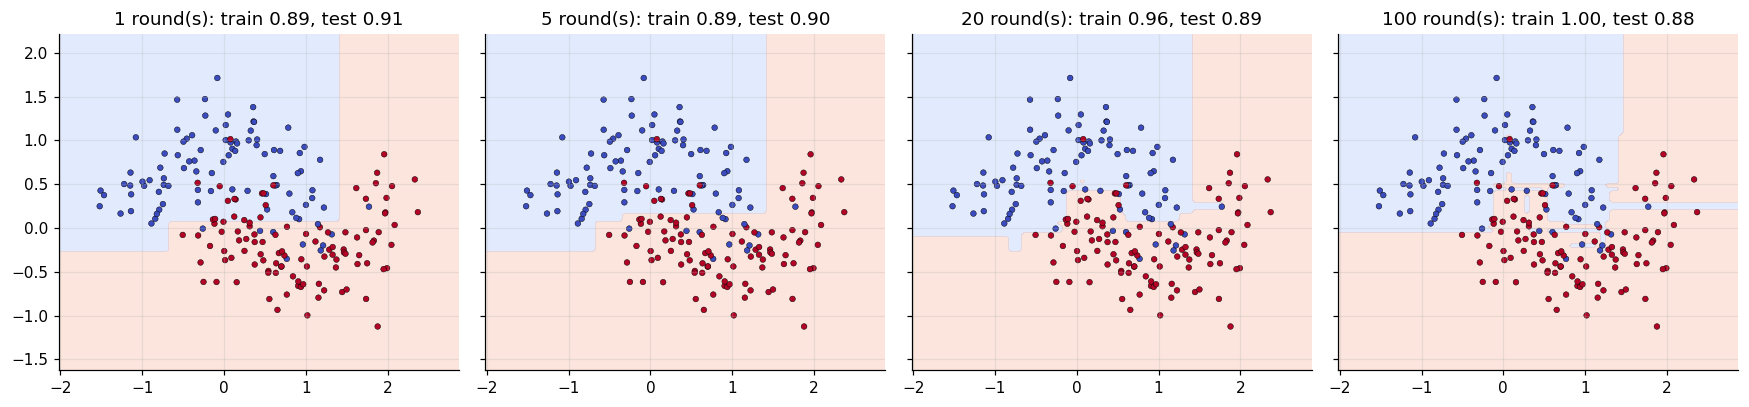

In [3]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
def plot_boundary(ax, model, X, y, cmap="coolwarm", n=150, pad=0.5):
    """Colour the plane by the model's predicted class, then draw the data on top."""
    gx, gy = np.meshgrid(np.linspace(X[:, 0].min() - pad, X[:, 0].max() + pad, n), np.linspace(X[:, 1].min() - pad, X[:, 1].max() + pad, n))
    pred = np.asarray(model.predict(np.c_[gx.ravel(), gy.ravel()])).reshape(gx.shape)
    K = len(np.unique(y))
    ax.contourf(gx, gy, pred, alpha=0.25, cmap=cmap, levels=np.arange(-0.5, K + 0.5) if K > 2 else [-0.5, 0.5, 1.5])
    ax.scatter(*X.T, c=y, cmap=cmap, s=14, edgecolor="k", linewidth=0.3)

Xm, ym = make_moons(n_samples=400, noise=0.3, random_state=0)
Xtr, Xte, ytr, yte = train_test_split(Xm, ym, test_size=0.5, random_state=0)
acc = lambda m, X, y: (m.predict(X) == y).mean()

fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
for ax, n in zip(axes, [1, 5, 20, 100]):
    m = GradientBoostingClassifier(n_estimators=n, learning_rate=0.2, max_depth=3).fit(Xtr, ytr)
    plot_boundary(ax, m, Xtr, ytr, n=90); ax.set_title(f"{n} round(s): train {acc(m, Xtr, ytr):.2f}, test {acc(m, Xte, yte):.2f}")
plt.tight_layout(); plt.show()

### 2. The training loss falls with every round

`loss_history_` records the cross-entropy after each round. Smaller learning rate means a slower, smoother descent.

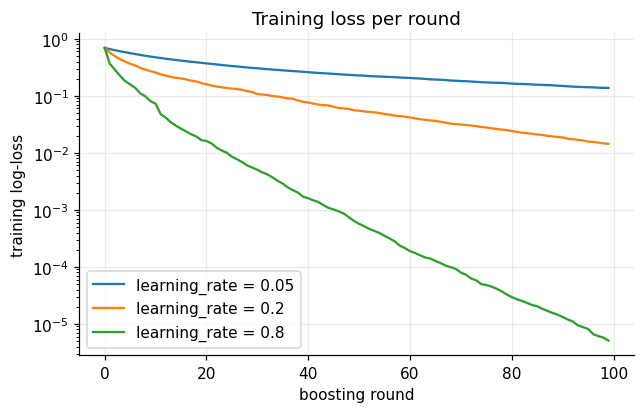

In [4]:
plt.figure(figsize=(6.5, 3.8))
for lr in (0.05, 0.2, 0.8):
    plt.plot(GradientBoostingClassifier(n_estimators=100, learning_rate=lr, max_depth=3).fit(Xtr, ytr).loss_history_, label=f"learning_rate = {lr}")
plt.xlabel("boosting round"); plt.ylabel("training log-loss"); plt.yscale("log"); plt.legend(); plt.title("Training loss per round"); plt.show()

### 3. Three classes

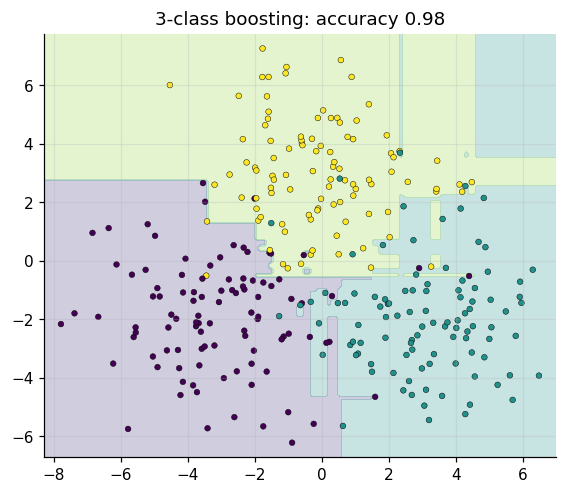

In [5]:
from sklearn.datasets import make_blobs

Xb, yb = make_blobs(n_samples=300, centers=[[-3, -2], [3, -2], [0, 3.5]], cluster_std=1.8, random_state=2)
m3 = GradientBoostingClassifier(n_estimators=40, learning_rate=0.2, max_depth=2).fit(Xb, yb)
fig, ax = plt.subplots(figsize=(6, 5)); plot_boundary(ax, m3, Xb, yb, cmap="viridis"); ax.set_title(f"3-class boosting: accuracy {acc(m3, Xb, yb):.2f}"); plt.show()

## Check against a reference implementation

Same data, same settings as scikit-learn (or scipy / the real library). The assertions fail if the two disagree.

In [6]:
from sklearn.datasets import load_wine
from sklearn.ensemble import GradientBoostingClassifier as SklearnGBC
from sklearn.model_selection import train_test_split

data = load_wine()  # 3 classes
X_train, X_test, y_train, y_test = train_test_split(
    data.data, data.target, test_size=0.3, random_state=42
)

ours = GradientBoostingClassifier(n_estimators=50, learning_rate=0.1, max_depth=3).fit(X_train, y_train)
theirs = SklearnGBC(n_estimators=50, learning_rate=0.1, max_depth=3, random_state=0).fit(X_train, y_train)

acc_ours = (ours.predict(X_test) == y_test).mean()
acc_theirs = (theirs.predict(X_test) == y_test).mean()
print("wine (3 classes) test accuracy: ours=%.4f sklearn=%.4f" % (acc_ours, acc_theirs))
print("training log-loss: %.4f -> %.4f over %d rounds"
      % (ours.loss_history_[0], ours.loss_history_[-1], len(ours.loss_history_)))
assert abs(acc_ours - acc_theirs) < 0.04

wine (3 classes) test accuracy: ours=0.9074 sklearn=0.9074
training log-loss: 1.0860 -> 0.0012 over 50 rounds


## Tests

Plain `assert` tests that check the invariants of the algorithm.

In [7]:
import numpy as np


def test_zero_rounds_predicts_the_class_priors():
    X = np.zeros((10, 2))
    y = np.array([0] * 7 + [1] * 3)
    probs = GradientBoostingClassifier(n_estimators=0).fit(X, y).predict_proba(X)
    assert np.allclose(probs, [0.7, 0.3])


def test_binary_xor_like_problem_needs_interactions():
    # XOR: boosted depth-2 trees can model it, a linear model cannot
    rng = np.random.default_rng(0)
    X = rng.uniform(-1, 1, size=(400, 2))
    y = (X[:, 0] * X[:, 1] > 0).astype(int)
    model = GradientBoostingClassifier(n_estimators=60, max_depth=2).fit(X, y)
    assert (model.predict(X) == y).mean() > 0.97


def test_multiclass_string_labels_probabilities_and_loss():
    rng = np.random.default_rng(1)
    centers = np.array([[-4, 0], [4, 0], [0, 5]])
    X = np.vstack([rng.normal(c, 0.8, (50, 2)) for c in centers])
    y = np.repeat(np.array(["red", "green", "blue"]), 50)
    model = GradientBoostingClassifier(n_estimators=40).fit(X, y)

    probs = model.predict_proba(X)
    assert probs.shape == (150, 3) and np.allclose(probs.sum(axis=1), 1.0)
    assert (model.predict(X) == y).mean() > 0.98
    assert model.loss_history_[-1] < 0.2 * model.loss_history_[0]  # training deviance falls fast

In [8]:
tests = [(name, fn) for name, fn in list(globals().items()) if name.startswith("test_") and callable(fn)]
for name, fn in tests:
    fn()
    print("PASS", name)
print(f"\nall {len(tests)} tests passed")

PASS test_zero_rounds_predicts_the_class_priors
PASS test_binary_xor_like_problem_needs_interactions
PASS test_multiclass_string_labels_probabilities_and_loss

all 3 tests passed


## Takeaways

- **Use it** like the regressor, for classification on tabular data; with enough rounds it fits very flexibly, so watch the test curve and use a small learning rate plus shallow trees.
- **What changes vs regression:** the residual becomes `y_onehot − softmax(F)` (the negative gradient of log-loss), and each leaf takes a Newton step `Σresidual / Σp(1−p)` (scaled by `(K−1)/K`).
- **Interview line:** *"Boosting on the log-loss: per class, fit a tree to `y − p`; output logits are summed tree contributions; softmax gives probabilities."*